In [ ]:
import pandas as pd
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import os
# import tarfile
import matplotlib
import re


In [2]:
# Initializing the graph from data

nodes = pd.read_csv(
    "../data/hep-th-slacdates.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["id", "date"], 
    dtype=str  
)


edges = pd.read_csv(
    "../data/hep-th-citations.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["From", "To"], 
    dtype=str
)

# 3. Get unique node IDs from both columns of the edge list
node_ids = pd.unique(edges[["From", "To"]].values.ravel())

# 4. Get actual nodes listed in edge list
nodes_used = nodes[nodes["id"].isin(node_ids)].copy()

# 5. Make a directed graph smoothly
g_directed = nx.DiGraph()

# Convert the filtered nodes dataframe into a dictionary of attributes and load them
node_attributes = nodes_used.set_index("id").to_dict("index")
g_directed.add_nodes_from(node_attributes.keys())
nx.set_node_attributes(g_directed, node_attributes)

# Add the edges directly from the edge dataframe tuples
g_directed.add_edges_from(edges.itertuples(index=False, name=None))

# Print properties to verify success
print("--- GRAPH INITIALIZATION SUCCESSFUL ---")
print(f"Nodes in graph: {g_directed.number_of_nodes()}")
print(f"Edges in graph: {g_directed.number_of_edges()}")

--- GRAPH INITIALIZATION SUCCESSFUL ---
Nodes in graph: 27770
Edges in graph: 352807


In [ ]:
# Null values check
# print(f"Nulls in From column: {edges['From'].isna().sum()}")
# print(f"Nulls in To column:   {edges['To'].isna().sum()}")

Nulls in From column: 0
Nulls in To column:   0


In [ ]:
# Identify cross-listed papers (starting with "11")
# crosslisted_dates = nodes[nodes["id"].str.startswith("11", na=False)].shape[0]
# crosslisted_citations = edges[edges["From"].str.startswith("11", na=False) | edges["To"].str.startswith("11", na=False)].shape[0]
# print(f"Crosslisted rows in dates file: {crosslisted_dates}")
# print(f"Crosslisted rows in citations file: {crosslisted_citations}")

Crosslisted rows in dates file: 0
Crosslisted rows in citations file: 0


In [3]:
# Get all unique nodes active in edge pairs
edges_nodes = pd.unique(edges[["From", "To"]].values.ravel())
vertices_nodes = nodes["id"].unique()

In [ ]:
# Find structural mismatch anomalies
# problem_nodes = np.setdiff1d(edges_nodes, vertices_nodes)
# print(f"\n--- TARGETED GRAPH MATCHING DIAGNOSTIC ---")
# print(f"Total unique nodes found in edge links: {len(edges_nodes)}")
# print(f"Total unique nodes found in dates file: {len(vertices_nodes)}")
# print(f"Number of offending nodes missing metadata: {len(problem_nodes)}")


--- TARGETED GRAPH MATCHING DIAGNOSTIC ---
Total unique nodes found in edge links: 27770
Total unique nodes found in dates file: 29555
Number of offending nodes missing metadata: 0


# Summary of the network properties

In [3]:
in_deg = dict(g_directed.in_degree())
out_deg = dict(g_directed.out_degree())
in_vals, out_vals = list(in_deg.values()), list(out_deg.values())
is_strongly_connected = nx.is_strongly_connected(g_directed)
is_weakly_connected = nx.is_weakly_connected(g_directed)

scc = list(nx.strongly_connected_components(g_directed))
wcc = list(nx.weakly_connected_components(g_directed))
clustering = list(nx.clustering(g_directed).values())
# avg_path_length = nx.average_shortest_path_length(g_directed)

summary_data = {
    "Network Property": [
        "Total Vertices (Papers)", "Total Edges (Citations)", "Network Density",
        "Strongly Connected ?", "Weakly Connected ?",
        "Mean In-Degree (Citations Received)", "Max In-Degree (Top Paper)",
        "Mean Out-Degree (References Given)", "Max Out-Degree (Longest Bibliography)",
        "Total Weakly Connected Components", "Size of Largest Connected Component (WCC)",
        "Total Strongly Connected Components (Cycles)", "Size of Largest Cyclic Component (SCC)",
        "Mean Local Clustering Coefficient"
    ],
    "Value": [
        g_directed.number_of_nodes(), g_directed.number_of_edges(), f"{nx.density(g_directed):.6f}",
        is_strongly_connected, is_weakly_connected,  
        f"{np.mean(in_vals):.2f}", np.max(in_vals),
        f"{np.mean(out_vals):.2f}", np.max(out_vals),
        len(wcc), max(len(c) for c in wcc),
        len(scc), max(len(c) for c in scc),
        f"{np.mean(clustering):.4f}",
        # f"{avg_path_length:.4f}"
    ]
}

network_summary = pd.DataFrame(summary_data)
print("\n=== THE TOPOLOGICAL PROFILE OF THE NETWORK ===")
print(network_summary.to_string(index=False))


=== THE TOPOLOGICAL PROFILE OF THE NETWORK ===
                            Network Property    Value
                     Total Vertices (Papers)    27770
                     Total Edges (Citations)   352807
                             Network Density 0.000458
                        Strongly Connected ?    False
                          Weakly Connected ?    False
         Mean In-Degree (Citations Received)    12.70
                   Max In-Degree (Top Paper)     2414
          Mean Out-Degree (References Given)    12.70
       Max Out-Degree (Longest Bibliography)      562
           Total Weakly Connected Components      143
   Size of Largest Connected Component (WCC)    27400
Total Strongly Connected Components (Cycles)    20086
      Size of Largest Cyclic Component (SCC)     7464
           Mean Local Clustering Coefficient   0.1569


In [12]:
in_degree_vals = g_directed.in_degree()
prev = 0
ans = 0
paperId = ''
for id, in_deg in in_degree_vals:
    if (in_deg > prev):
        paperId = id
        ans = in_deg
        prev = in_deg

print(paperId, ans)

9711200 2414


In [14]:
out_degree_vals = g_directed.out_degree()
prev1 = 0
ans1 = 0
paperId1 = ''
for id, out_deg in out_degree_vals:
    if (out_deg > prev1):
        paperId1 = id
        ans1 = out_deg
        prev1 = out_deg

print(paperId1, ans1)

9905111 562


In [15]:
largest_wcc_nodes = max(nx.weakly_connected_components(g_directed), key=len)
g_largest_wcc = g_directed.subgraph(largest_wcc_nodes)

g_undirected_wcc = g_largest_wcc.to_undirected()

avg_path_length = nx.average_shortest_path_length(g_undirected_wcc)

print(f"Average Path Length of the wCC {avg_path_length}")

Average Path Length of the wCC 4.278680083960654


# In-Degree Plot

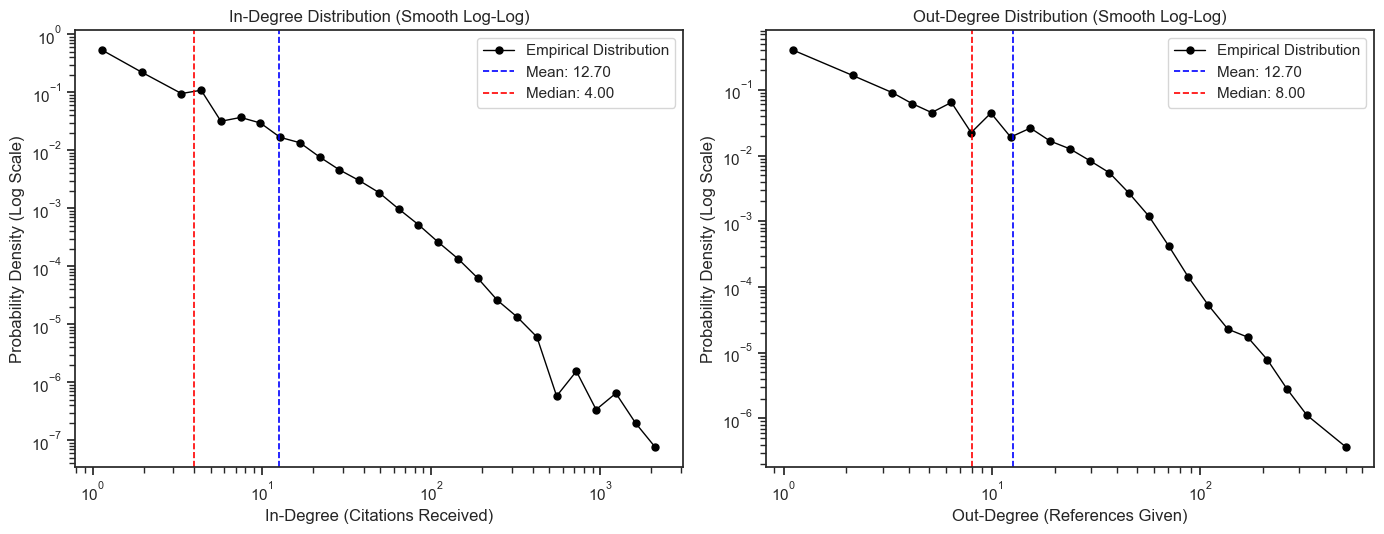

In [15]:
sns.set_theme(style="ticks")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- HELPER FUNCTION FOR CLEAN LOG-LINED DISTRIBUTIONS ---
def plot_clean_log_distribution(values, ax, title, xlabel):
    vals_series = pd.Series(values)
    vals_filtered = vals_series[vals_series > 0]
    
    # 1. Generate 30 clean log-spaced bins
    bins = np.logspace(np.log10(vals_filtered.min()), np.log10(vals_filtered.max()), 30)
    
    # 2. Use pandas.cut to digitize the data points into these bins
    bin_assignments = pd.cut(vals_filtered, bins=bins, include_lowest=True)
    
    # 3. Calculate the normalized density for each bin
    counts = bin_assignments.value_counts(sort=False)
    bin_widths = np.diff(bins)
    densities = counts.values / (len(vals_filtered) * bin_widths)
    
    # 4. Find the exact geometric center point of each bin for the scatter markers
    bin_centers = np.sqrt(bins[:-1] * bins[1:])
    
    # 5. Filter out empty bins to avoid drawing broken lines to log(0)
    valid = densities > 0
    
    # 6. Plot a clean continuous line with clear dot markers
    ax.plot(bin_centers[valid], densities[valid], 'o-', color='black', 
            markersize=5, linewidth=1, label='Empirical Distribution')
    
    # Structural overlays
    ax.axvline(np.mean(values), color='blue', linestyle='--', linewidth=1.2, 
               label=f"Mean: {np.mean(values):.2f}")
    ax.axvline(np.median(values), color='red', linestyle='--', linewidth=1.2, 
               label=f"Median: {np.median(values):.2f}")
    
    # Axis formatting
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability Density (Log Scale)")
    ax.legend()

# --- EXECUTE ON YOUR METRICS ---
plot_clean_log_distribution(in_vals, axes[0], "In-Degree Distribution (Smooth Log-Log)", "In-Degree (Citations Received)")
plot_clean_log_distribution(out_vals, axes[1], "Out-Degree Distribution (Smooth Log-Log)", "Out-Degree (References Given)")

plt.tight_layout()
plt.show()



In [3]:
# Assigning node attribute for easy extraction by year

nodes_used["year"] = pd.to_numeric(nodes_used["date"].str.slice(0,4), errors='coerce')
nx.set_node_attributes(g_directed, nodes_used.set_index("id")["year"].to_dict(), "year")

In [92]:
# os.makedirs('oslom_inputs', exist_ok = True)

# for current_year in range(1992, 2004):
#     active_ids = nodes_used[nodes_used['year'] <= current_year]["id"]
#     year_edges = edges[edges["From"].isin(active_ids) & edges["To"].isin(active_ids)]

#     filePath = f"oslom_inputs/network_{current_year}.txt"
#     year_edges.to_csv(filePath, sep = " ", header = False, index = False)

#     print(f"Exported clean snapshot for Year {current_year} -> {filePath}")


In [91]:
# for current_year in range(1995, 2004):
    
#     # Every window is now guaranteed to be exactly 4 years long
#     start_year = current_year - 3
    
#     # Filter IDs that fall strictly within this uniform 4-year bracket
#     active_ids = nodes_used[(nodes_used['year'] >= start_year) & (nodes_used['year'] <= current_year)]["id"]
    
#     # Isolate edges where BOTH the citing paper and cited paper belong to this active window
#     year_edges = edges[edges["From"].isin(active_ids) & edges["To"].isin(active_ids)]
    
#     # Construct the descriptive, symmetric file name
#     filePath = f"oslom_inputs/network_{start_year}_{current_year}.txt"
    
#     # Export to a clean, space-separated format for OSLOM
#     year_edges.to_csv(filePath, sep=" ", header=False, index=False)
    
#     print(f"Exported uniform sliding window snapshot ({start_year} to {current_year}) -> {filePath}")

In [93]:
# For extracting the abstract data

# tar = tarfile.open("../data/hep-th-abs.tar.gz", "r:gz")
# tar.extractall("../abstracts")
# tar.close()


{'9205091': 0, '9207091': 1, '9206102': 2, '9503230': 3, '9203031': 4, '9206019': 5, '9201052': 6, '9210106': 7, '9210068': 8, '9202090': 9, '9212050': 10, '9206045': 11, '9209084': 12, '9206076': 12, '9204023': 13, '9208071': 14, '9202012': 15, '9210094': 16, '9202043': 17, '9207047': 18, '9301013': 19, '9212127': 20, '9211047': 21, '9204060': 21, '9209059': 21, '9201014': 21, '9210053': 21, '9205004': 21, '9202039': 21, '9412193': 22, '9209027': 23, '9211063': 24, '9208045': 25, '9209063': 26, '9210019': 26, '9212007': 27, '9209062': 28, '9204081': 29, '9207057': 30, '9207087': 31, '9208050': 32, '9210107': 33, '9202062': 34, '9203023': 35, '9205008': 36, '9201058': 37, '9212068': 37, '9205074': 38, '9202074': 39, '9210032': 39, '9211124': 40, '9206047': 41, '9211114': 41, '9212124': 41, '9208021': 41, '9206029': 42, '9206024': 42, '9212093': 42, '9210150': 42, '9205055': 43, '9206110': 44, '9203013': 45, '9211090': 46, '9204058': 47, '9205104': 47, '9206027': 48, '9212023': 49, '920

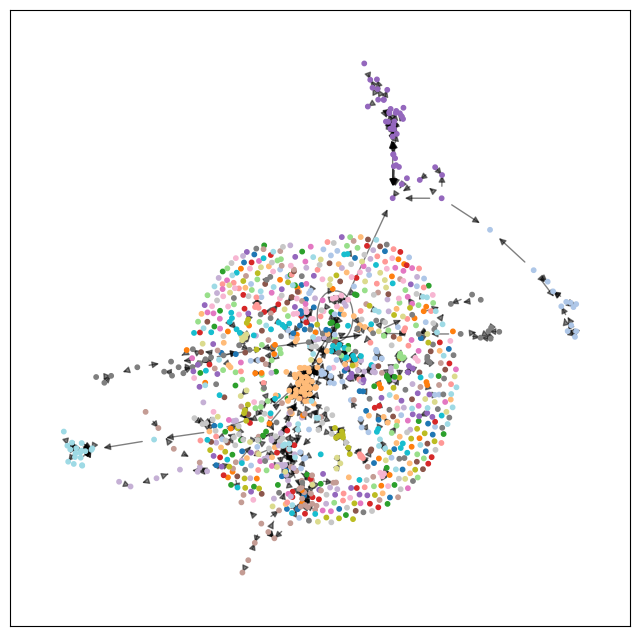

In [11]:
nodes_1992 = [id for id, year in nx.get_node_attributes(g_directed, "year").items() if year <= 1992]

g_directed_1992 = g_directed.subgraph(nodes_1992)

partitions = nx.community.louvain_communities(g_directed_1992, seed=35)
# print(partitions)

community_map_1992 = {}
for community_id, community in enumerate(partitions):
    for node in community:
        community_map_1992[node] = community_id

print(community_map_1992)
node_colors = [community_map_1992[node] for node in g_directed_1992.nodes()]

cmap = matplotlib.colormaps['tab20']

plt.figure(figsize=(8,8))

pos = nx.spring_layout(g_directed_1992, seed = 35)
nx.draw_networkx_nodes(g_directed_1992, pos, node_size=10, cmap=cmap, node_color = node_colors)
nx.draw_networkx_edges(g_directed_1992, pos, alpha=0.5)
plt.show()

In [12]:
comms_data = {}

for i in range(0, len(partitions)):
    comms_data[f"Community-{i}"] = list(partitions[i])

print(len(comms_data), comms_data)

675 {'Community-0': ['9205091'], 'Community-1': ['9207091'], 'Community-2': ['9206102'], 'Community-3': ['9503230'], 'Community-4': ['9203031'], 'Community-5': ['9206019'], 'Community-6': ['9201052'], 'Community-7': ['9210106'], 'Community-8': ['9210068'], 'Community-9': ['9202090'], 'Community-10': ['9212050'], 'Community-11': ['9206045'], 'Community-12': ['9209084', '9206076'], 'Community-13': ['9204023'], 'Community-14': ['9208071'], 'Community-15': ['9202012'], 'Community-16': ['9210094'], 'Community-17': ['9202043'], 'Community-18': ['9207047'], 'Community-19': ['9301013'], 'Community-20': ['9212127'], 'Community-21': ['9211047', '9204060', '9209059', '9201014', '9210053', '9205004', '9202039'], 'Community-22': ['9412193'], 'Community-23': ['9209027'], 'Community-24': ['9211063'], 'Community-25': ['9208045'], 'Community-26': ['9209063', '9210019'], 'Community-27': ['9212007'], 'Community-28': ['9209062'], 'Community-29': ['9204081'], 'Community-30': ['9207057'], 'Community-31': ['

In [13]:
# Jaccard Similarity function

def Jaccard_Similarity(old, new):
    A = set(old)
    B = set(new)

    C = A.intersection(B)
    D = A.union(B)

    return (float(len(C))) / (float(len(D)));

In [14]:
# Create a map which will note down the index from 0 for all the papers
paperId_map = {}
nodes_1992.sort()
for i in range(0, len(nodes_1992)):
    paperId_map[nodes_1992[i]] = i

print(paperId_map)

{'0001113': 0, '0012228': 1, '0208020': 2, '0209014': 3, '9201001': 4, '9201002': 5, '9201003': 6, '9201004': 7, '9201005': 8, '9201006': 9, '9201007': 10, '9201008': 11, '9201009': 12, '9201010': 13, '9201011': 14, '9201013': 15, '9201014': 16, '9201015': 17, '9201016': 18, '9201017': 19, '9201019': 20, '9201020': 21, '9201021': 22, '9201024': 23, '9201025': 24, '9201026': 25, '9201027': 26, '9201028': 27, '9201029': 28, '9201030': 29, '9201031': 30, '9201032': 31, '9201033': 32, '9201034': 33, '9201035': 34, '9201036': 35, '9201037': 36, '9201039': 37, '9201040': 38, '9201041': 39, '9201042': 40, '9201044': 41, '9201045': 42, '9201047': 43, '9201048': 44, '9201049': 45, '9201050': 46, '9201051': 47, '9201052': 48, '9201054': 49, '9201056': 50, '9201058': 51, '9201059': 52, '9201061': 53, '9201062': 54, '9201063': 55, '9201064': 56, '9201065': 57, '9201066': 58, '9201067': 59, '9201068': 60, '9201069': 61, '9201070': 62, '9201071': 63, '9201072': 64, '9201074': 65, '9201077': 66, '920

## Trying to implement COIN model for 1992 data

Membership matrix

In [12]:
n = len(nodes_1992) # no. of papers (rows)
m = len(partitions) # no. of communities (columns)

In [15]:
# Membership matrix for 1992

# n --> nodes; m --> communities 
# n = 1051; m = 681

membership_1992 = np.zeros((n, m), dtype=int)

for paperId, x in paperId_map.items():
    y = community_map_1992.get(paperId)
    # print(y)
    membership_1992[x][y] = 1

print(membership_1992.sum())

# Membership matrix for 1992 created

1051


Centrality Tensor

In [16]:
# Creating a centrality tensor for 1992

# Centrality tensor is a completely different matrix from membership matrix. 
# Hence a slight modification is that, instead of author i,
# I will be using the paperId itself and try implementing COIN model.

centrality_tensor = np.zeros((n, m, m), dtype=int)

for citing, cited in g_directed_1992.edges():
    paperId = paperId_map.get(cited)
    u = int(community_map_1992.get(cited))
    v = int(community_map_1992.get(citing))

    centrality_tensor[paperId, u, v] += 1


In [17]:
print(centrality_tensor.sum(), len(g_directed_1992.edges()))

535 535


Impact Matrix

In [18]:
numerator = np.einsum('xu,xuv->uv', membership_1992, centrality_tensor)

In [19]:
numerator.shape

(681, 681)

In [20]:
community_sizes = membership_1992.sum(axis=0)
community_sizes.shape

(681,)

In [21]:
# Impact Matrix

J = numerator / community_sizes[:, None]
J.shape

(681, 681)

In [23]:
with np.printoptions(threshold=np.inf):
    print(J)

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.   

# Working on Abstract Data

In [26]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [27]:
# pre-processing function for SciBERT type models

def getTitleAndAbstract(text):

    # text = re.sub(r'\n', ' ', text)

    title = re.search(r'Title:\s*(.*)', text)
    sections = text.split('\\\\')
    abstract = sections[-2] if len(sections) > 2 else ""

    abstract_cleaned = re.sub(r'\n', ' ', abstract)

    return [f'{title.group(1).strip()}. {abstract_cleaned.strip()}'.strip()]



In [28]:
# pre-processing function for LDA type models

def lda_embeddings(text):

    # for excluding other unnecessary metadata like 
    # Journal Ref:, Date:, From:, etc. 
     
    title = re.search(r'Title:\s*(.*)', text)
    sections = text.split('\\\\')
    abstract = sections[-2] if len(sections) > 2 else ""
    abstract_cleaned = re.sub(r'\n', ' ', abstract)

    text = title.group(1).strip() + '\n' + abstract_cleaned.strip()

    # to lowercase
    text = text.lower()

    # remove latex math expressions
    text = re.sub(r'\$.*?\$', ' ', text)

    # remove latex commands
    text = re.sub(r'\\[A-Za-z]+', ' ', text)

    # remove punctuations
    text = re.sub(r'[^\w\s]', ' ', text)

    # remove standalone numbers
    text = re.sub(r'\b\d+\b', ' ', text)

    # remove underscores
    text = re.sub(r'_+', ' ', text)

    # correcting whitespaces
    text = re.sub(r'\s+', ' ', text)

    # tokenization
    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return tokens



In [ ]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1992'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1992,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1992 = pd.DataFrame(papers_data)
df_1992.head()


,paper_id,year,title,subject,scibert_data,embeddings
0,9201001,1992,Combinatorics of the Modular Group II: the Kon...,High Energy Physics - Theory; Quantum Algebra,[Combinatorics of the Modular Group II: the Ko...,"[combinatorics, modular, group, kontsevich, in..."
1,9201002,1992,Inomogeneous Quantum Groups as Symmetries of P...,,[Inomogeneous Quantum Groups as Symmetries of ...,"[inomogeneous, quantum, group, symmetry, phono..."
2,9201003,1992,"Intersection Theory, Integrable Hierarchies an...",,"[Intersection Theory, Integrable Hierarchies a...","[intersection, theory, integrable, hierarchy, ..."
3,9201004,1992,The Heterotic Green-Schwarz Superstring on an ...,,[The Heterotic Green-Schwarz Superstring on an...,"[heterotic, green, schwarz, superstring, super..."
4,9201005,1992,Ward Identities in Two-Dimensional String Theory,,[Ward Identities in Two-Dimensional String The...,"[ward, identity, two, dimensional, string, the..."


In [ ]:
df_1992.to_parquet('papers1992.parquet')

In [29]:
print(len(df_1992['scibert_data'][0][0]))

625


In [ ]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1993'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1993,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1993 = pd.DataFrame(papers_data)

df_1993.to_parquet('abstract structured data/papers1993.parquet')

In [32]:
df_1993.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9301001,1993,Gonihedric String and Asymptotic Freedom,,[Gonihedric String and Asymptotic Freedom. Few...,"[gonihedric, string, asymptotic, freedom, natu..."
1,9301002,1993,Scaling behavior of quantum four-geometries,,[Scaling behavior of quantum four-geometries. ...,"[scaling, behavior, quantum, four, geometry, p..."
2,9301003,1993,Summing Over Inequivalent Maps in the String T...,,[Summing Over Inequivalent Maps in the String ...,"[summing, inequivalent, map, string, theory, i..."
3,9301004,1993,Large Order Behaviour of 2D Gravity Coupled to...,,[Large Order Behaviour of 2D Gravity Coupled t...,"[large, order, behaviour, gravity, coupled, ma..."
4,9301005,1993,"Duality, Marginal Perturbations and Gauging",,"[Duality, Marginal Perturbations and Gauging. ...","[duality, marginal, perturbation, gauging, stu..."


In [33]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1994'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1994,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1994 = pd.DataFrame(papers_data)
df_1994.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9401001,1994,Remarks on the Collective Quantization of the ...,,[Remarks on the Collective Quantization of the...,"[remark, collective, quantization, skyrme, mod..."
1,9401002,1994,"Hard Thermal Loops, Static Response and the Co...",,"[Hard Thermal Loops, Static Response and the C...","[hard, thermal, loop, static, response, compos..."
2,9401003,1994,Local heterotic geometry in holomorphic coordi...,,[Local heterotic geometry in holomorphic coord...,"[local, heterotic, geometry, holomorphic, coor..."
3,9401004,1994,Vertex Operators are Not Closeable,,[Vertex Operators are Not Closeable. We prove ...,"[vertex, operator, closeable, prove, uncloseab..."
4,9401005,1994,Q-Exact Actions for BF Theories,,[Q-Exact Actions for BF Theories. The actions ...,"[exact, action, theory, action, classical, con..."


In [ ]:
df_1994.to_parquet('abstract structured data/papers1994.parquet')

In [36]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1995'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1995,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1995 = pd.DataFrame(papers_data)
df_1995.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9501001,1995,Anomaly and Exotic Statistics in One Dimension,,[Anomaly and Exotic Statistics in One Dimensio...,"[anomaly, exotic, statistic, one, dimension, s..."
1,9501002,1995,Super-${\tau}_{3}$QED and the dimensional redu...,,[Super-${\tau}_{3}$QED and the dimensional red...,"[super, qed, dimensional, reduction, work, sup..."
2,9501003,1995,"BRST quantization of gauge theories like SL(2,...",,[BRST quantization of gauge theories like SL(2...,"[brst, quantization, gauge, theory, like, inne..."
3,9501004,1995,Solving general gauge theories on inner produc...,,[Solving general gauge theories on inner produ...,"[solving, general, gauge, theory, inner, produ..."
4,9501005,1995,"Steps towards Lattice Virasoro Algebras: su(1,1)",,[Steps towards Lattice Virasoro Algebras: su(1...,"[step, towards, lattice, virasoro, algebra, ex..."


In [37]:
df_1995.to_parquet('abstract structured data/papers1995.parquet')

In [38]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1996'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1996,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1996 = pd.DataFrame(papers_data)
df_1996.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9601001,1996,Integrable Z_n-Chiral Potts Model: The Missing...,,[Integrable Z_n-Chiral Potts Model: The Missin...,"[integrable, chiral, potts, model, missing, ra..."
1,9601002,1996,Actions for QCD-like strings,,[Actions for QCD-like strings. We introduce a ...,"[action, qcd, like, string, introduce, random,..."
2,9601003,1996,D-brane actions,,[D-brane actions. Effective world-brane action...,"[brane, action, effective, world, brane, actio..."
3,9601004,1996,An Extreme Black Hole with Electric Dipole Moment,,[An Extreme Black Hole with Electric Dipole Mo...,"[extreme, black, hole, electric, dipole, momen..."
4,9601005,1996,An Extension of Distribution Theory Related to...,,[An Extension of Distribution Theory Related t...,"[extension, distribution, theory, related, gau..."


In [39]:
df_1996.to_parquet('abstract structured data/papers1996.parquet')

In [40]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1997'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1997,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1997 = pd.DataFrame(papers_data)
df_1997.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9701001,1997,"Ricci flat metrics in various dimensions, depe...",,"[Ricci flat metrics in various dimensions, dep...","[ricci, flat, metric, various, dimension, depe..."
1,9701002,1997,Comment on ``Additional analytically exact sol...,,[Comment on ``Additional analytically exact so...,"[comment, additional, analytically, exact, sol..."
2,9701003,1997,On Generalized Quantum Deformations and Symmet...,,[On Generalized Quantum Deformations and Symme...,"[generalized, quantum, deformation, symmetry, ..."
3,9701004,1997,Large-Order Perturbation Theory in Infrared-Un...,,[Large-Order Perturbation Theory in Infrared-U...,"[large, order, perturbation, theory, infrared,..."
4,9701005,1997,Spontaneous Collapse of Supersymmetry,,[Spontaneous Collapse of Supersymmetry. It is ...,"[spontaneous, collapse, supersymmetry, shown, ..."


In [41]:
df_1997.to_parquet('abstract structured data/papers1997.parquet')

In [42]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1998'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1998,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1998 = pd.DataFrame(papers_data)
df_1998.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9801001,1998,Forced Topological Nontrivial Field Configurat...,,[Forced Topological Nontrivial Field Configura...,"[forced, topological, nontrivial, field, confi..."
1,9801002,1998,Duality of Chiral N=1 Supersymmetric Gauge The...,,[Duality of Chiral N=1 Supersymmetric Gauge Th...,"[duality, chiral, supersymmetric, gauge, theor..."
2,9801003,1998,Effective interactions of a light gravitino,,[Effective interactions of a light gravitino. ...,"[effective, interaction, light, gravitino, rev..."
3,9801004,1998,Chiral anomaly and unambiguous rational terms,,[Chiral anomaly and unambiguous rational terms...,"[chiral, anomaly, unambiguous, rational, term,..."
4,9801005,1998,Quantum field theory can be UV finite if it is...,,[Quantum field theory can be UV finite if it i...,"[quantum, field, theory, finite, taken, effect..."


In [43]:
df_1998.to_parquet('abstract structured data/papers1998.parquet')

In [44]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1999'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1999,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1999 = pd.DataFrame(papers_data)
df_1999.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,9901001,1999,String Junctions and Their Duals in Heterotic ...,,[String Junctions and Their Duals in Heterotic...,"[string, junction, duals, heterotic, string, t..."
1,9901002,1999,Exact Absorption Probability in the Extremal S...,,[Exact Absorption Probability in the Extremal ...,"[exact, absorption, probability, extremal, six..."
2,9901003,1999,N=1 D=4 supermembrane in the coset approach,,[N=1 D=4 supermembrane in the coset approach. ...,"[supermembrane, coset, approach, supermembrane..."
3,9901004,1999,"Brane Waves, Yang-Mills theories and Causality",,"[Brane Waves, Yang-Mills theories and Causalit...","[brane, wave, yang, mill, theory, causality, p..."
4,9901005,1999,"Issues of Heterotic (0,2) Compactifications",,"[Issues of Heterotic (0,2) Compactifications. ...","[issue, heterotic, compactifications, brief, r..."


In [45]:
df_1999.to_parquet('abstract structured data/papers1999.parquet')

In [46]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/2000'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 2000,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_2000 = pd.DataFrame(papers_data)
df_2000.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,0001001,2000,"Compactification, Geometry and Duality: N=2",,"[Compactification, Geometry and Duality: N=2. ...","[compactification, geometry, duality, note, ba..."
1,0001002,2000,Domain Walls and Massive Gauged Supergravity P...,,[Domain Walls and Massive Gauged Supergravity ...,"[domain, wall, massive, gauged, supergravity, ..."
2,0001003,2000,"Comment on ""Metric Fluctuations in Brane Worlds""",,"[Comment on ""Metric Fluctuations in Brane Worl...","[comment, metric, fluctuation, brane, world, r..."
3,0001004,2000,Moving Mirrors and Thermodynamic Paradoxes,,[Moving Mirrors and Thermodynamic Paradoxes. Q...,"[moving, mirror, thermodynamic, paradox, quant..."
4,0001005,2000,Bundles of chiral blocks and boundary conditio...,,[Bundles of chiral blocks and boundary conditi...,"[bundle, chiral, block, boundary, condition, c..."


In [47]:
df_2000.to_parquet('abstract structured data/papers2000.parquet')

In [48]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/2001'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 2001,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_2001 = pd.DataFrame(papers_data)
df_2001.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,0101001,2001,On the Polarization of Unstable D0-Branes into...,,[On the Polarization of Unstable D0-Branes int...,"[polarization, unstable, branes, non, commutat..."
1,0101002,2001,BPS Vortices in Brane-Antibrane Effective Theory,,[BPS Vortices in Brane-Antibrane Effective The...,"[bps, vortex, brane, antibrane, effective, the..."
2,0101003,2001,String versus Einstein frame in an AdS/CFT ind...,,[String versus Einstein frame in an AdS/CFT in...,"[string, versus, einstein, frame, ad, cft, ind..."
3,0101004,2001,Black Hole Horizon in Superstring Inspired D-D...,,[Black Hole Horizon in Superstring Inspired D-...,"[black, hole, horizon, superstring, inspired, ..."
4,0101005,2001,Nonlocal two-dimensional Yang-Mills- and gener...,,[Nonlocal two-dimensional Yang-Mills- and gene...,"[nonlocal, two, dimensional, yang, mill, gener..."


In [49]:
df_2001.to_parquet('abstract structured data/papers2001.parquet')

In [50]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/2002'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 2002,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_2002 = pd.DataFrame(papers_data)
df_2002.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,0201001,2002,Integrable Heisenberg-van Vleck chains with va...,,[Integrable Heisenberg-van Vleck chains with v...,"[integrable, heisenberg, van, vleck, chain, va..."
1,0201002,2002,"Non-Commutative Space-Times, Black Hole, and E...",,"[Non-Commutative Space-Times, Black Hole, and ...","[non, commutative, space, time, black, hole, e..."
2,0201003,2002,The Hamilton-Jacobi treatment for non-abelian ...,,[The Hamilton-Jacobi treatment for non-abelian...,"[hamilton, jacobi, treatment, non, abelian, ch..."
3,0201004,2002,Slicing and Brane Dependence of the (A)dS/CFT ...,,[Slicing and Brane Dependence of the (A)dS/CFT...,"[slicing, brane, dependence, cft, corresponden..."
4,0201005,2002,Vortex Correlation Functions in Maxwell-Chern-...,High Energy Physics - Theory; Strongly Correla...,[Vortex Correlation Functions in Maxwell-Chern...,"[vortex, correlation, function, maxwell, chern..."


In [51]:
df_2002.to_parquet('abstract structured data/papers2002.parquet')

In [52]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/2003'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 2003,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_2003 = pd.DataFrame(papers_data)
df_2003.head()

,paper_id,year,title,subject,scibert_data,embeddings
0,0301001,2003,Precanonical quantization of Yang-Mills fields...,,[Precanonical quantization of Yang-Mills field...,"[precanonical, quantization, yang, mill, field..."
1,0301002,2003,Universality classes for horizon instabilities,,[Universality classes for horizon instabilitie...,"[universality, class, horizon, instability, in..."
2,0301003,2003,Strings in the Quantized pp-wave Backgrounds f...,,[Strings in the Quantized pp-wave Backgrounds ...,"[string, quantized, wave, background, membrane..."
3,0301004,2003,Relativistic phase space: dimensional recurrences,,[Relativistic phase space: dimensional recurre...,"[relativistic, phase, space, dimensional, recu..."
4,0301005,2003,Structure of supergravity theories,,[Structure of supergravity theories. We give a...,"[structure, supergravity, theory, give, elemen..."


In [53]:
df_2003.to_parquet('abstract structured data/papers2003.parquet')

# 1993 

{'9304130': 0, '9307146': 1, '9306139': 2, '9312096': 3, '9206019': 4, '9310093': 5, '9312092': 6, '9201035': 7, '9312035': 7, '9312128': 8, '9305052': 9, '9412193': 10, '9310142': 11, '9311063': 12, '9209063': 12, '9210019': 12, '9207087': 13, '9212129': 14, '9304014': 15, '9310088': 16, '9303130': 16, '9307144': 16, '9306152': 16, '9310151': 17, '9302067': 18, '9211090': 19, '9307132': 20, '9212060': 21, '9305177': 22, '9202036': 23, '9306150': 24, '9210136': 25, '9211105': 26, '9312062': 27, '9309015': 28, '9306036': 29, '9303078': 30, '9204033': 30, '9210099': 31, '9210152': 32, '9308152': 33, '9311047': 34, '9305003': 34, '9201052': 34, '9305039': 34, '9301083': 34, '9305030': 34, '9308011': 34, '9204049': 34, '9206014': 34, '9311009': 34, '9305105': 34, '9211072': 34, '9304057': 34, '9303136': 34, '9311052': 34, '9311137': 34, '9201071': 34, '9209122': 34, '9305087': 34, '9202015': 34, '9302106': 34, '9305023': 34, '9304072': 34, '9305109': 34, '9308001': 34, '9210120': 34, '9201

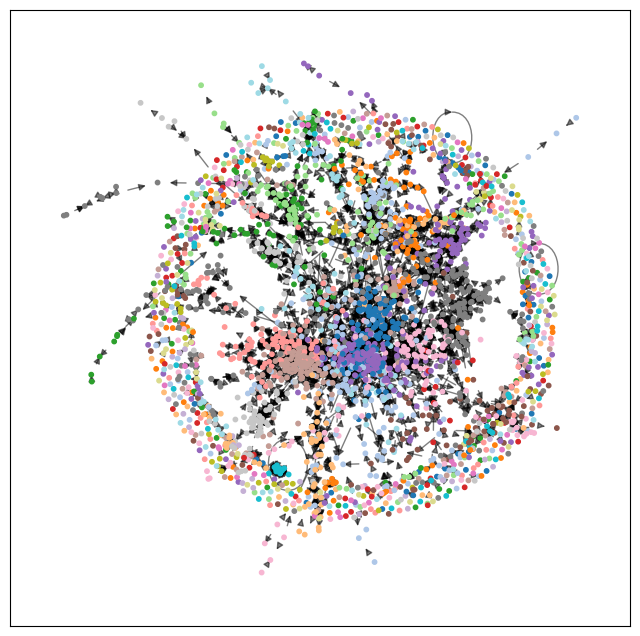

In [8]:
nodes_1993 = [id for id, year in nx.get_node_attributes(g_directed, "year").items() if year <= 1993]
# print(nodes_1993)

g_directed_1993 = g_directed.subgraph(nodes_1993)
partitions_1993 = nx.community.louvain_communities(g_directed_1993, seed=35)
# print(partitions_1993)

community_map_1993 = {}
for community_id, community in enumerate(partitions_1993):
    for node in community:
        community_map_1993[node] = community_id

print(community_map_1993)
node_colors = [community_map_1993[node] for node in g_directed_1993.nodes()]

cmap = matplotlib.colormaps['tab20']

plt.figure(figsize=(8,8))

pos = nx.spring_layout(g_directed_1993, seed = 35)
nx.draw_networkx_nodes(g_directed_1993, pos, node_size=10, cmap=cmap, node_color = node_colors)
nx.draw_networkx_edges(g_directed_1993, pos, alpha=0.5)
plt.show()

In [9]:
data_1993 = {}

for i in range(0, len(partitions_1993)):
    data_1993[f"Community-{i}"] = list(partitions_1993[i])

print(len(data_1993), data_1993)

821 {'Community-0': ['9304130'], 'Community-1': ['9307146'], 'Community-2': ['9306139'], 'Community-3': ['9312096'], 'Community-4': ['9206019'], 'Community-5': ['9310093'], 'Community-6': ['9312092'], 'Community-7': ['9201035', '9312035'], 'Community-8': ['9312128'], 'Community-9': ['9305052'], 'Community-10': ['9412193'], 'Community-11': ['9310142'], 'Community-12': ['9311063', '9209063', '9210019'], 'Community-13': ['9207087'], 'Community-14': ['9212129'], 'Community-15': ['9304014'], 'Community-16': ['9310088', '9303130', '9307144', '9306152'], 'Community-17': ['9310151'], 'Community-18': ['9302067'], 'Community-19': ['9211090'], 'Community-20': ['9307132'], 'Community-21': ['9212060'], 'Community-22': ['9305177'], 'Community-23': ['9202036'], 'Community-24': ['9306150'], 'Community-25': ['9210136'], 'Community-26': ['9211105'], 'Community-27': ['9312062'], 'Community-28': ['9309015'], 'Community-29': ['9306036'], 'Community-30': ['9303078', '9204033'], 'Community-31': ['9210099'], 

In [10]:
# Tracking communities framework

for community_id1, nodes1 in data_1993.items():
    for community_id2, nodes2 in comms_data.items():
        sim = Jaccard_Similarity(nodes2, nodes1)
        if sim != 0 and sim >= 0.5:
            print(f'Old {community_id2} is similar to new {community_id1} by a measure of {sim}')


Old Community-5 is similar to new Community-4 by a measure of 1.0
Old Community-673 is similar to new Community-7 by a measure of 0.5
Old Community-22 is similar to new Community-10 by a measure of 1.0
Old Community-561 is similar to new Community-12 by a measure of 0.6666666666666666
Old Community-30 is similar to new Community-13 by a measure of 1.0
Old Community-48 is similar to new Community-19 by a measure of 1.0
Old Community-55 is similar to new Community-21 by a measure of 1.0
Old Community-58 is similar to new Community-23 by a measure of 1.0
Old Community-61 is similar to new Community-25 by a measure of 1.0
Old Community-74 is similar to new Community-30 by a measure of 0.5
Old Community-79 is similar to new Community-31 by a measure of 1.0
Old Community-81 is similar to new Community-32 by a measure of 1.0
Old Community-96 is similar to new Community-40 by a measure of 1.0
Old Community-100 is similar to new Community-42 by a measure of 1.0
Old Community-104 is similar to n

# Implementation

Considering Louvain Clustering for this implementation.

Extracting all the clusters for each year in a structured way for easy implementation with COIN model.



In [ ]:
# extracting all the papers till 'year' 
# and extracting the subgraph till that 'year'

years = list(range(1992, 2004))

year_nodes = {}
year_graphs ={}

for year in years:
    year_nodes[year] = [id for id, y in nx.get_node_attributes(g_directed, "year").items() if y <= year]
    year_graphs[year] = g_directed.subgraph(year_nodes[year])

print(len(year_nodes))


12


In [ ]:
# getting Louvain clusters for each year and storing them in a map
# with community id to which it belongs as done previously 

year_partitions = {}
year_community_map = {}

for year in years:
    partitions = nx.community.louvain_communities(year_graphs[year], seed = 42)
    year_partitions[year] = partitions

    community_map = {}
    for community_id, community in enumerate(partitions):
        for node in community:
            community_map[node] = community_id
    
    year_community_map[year] = community_map

year_community_map

{1992: {'9205091': 0,
  '9207091': 1,
  '9206102': 2,
  '9503230': 3,
  '9203031': 4,
  '9206019': 5,
  '9201052': 6,
  '9210106': 7,
  '9210068': 8,
  '9202090': 9,
  '9212050': 10,
  '9206045': 11,
  '9209084': 12,
  '9206076': 12,
  '9204023': 13,
  '9208071': 14,
  '9202012': 15,
  '9210094': 16,
  '9202043': 17,
  '9207047': 18,
  '9301013': 19,
  '9212127': 20,
  '9203051': 21,
  '9204071': 21,
  '9209115': 21,
  '9207050': 21,
  '9201020': 21,
  '9202061': 21,
  '9209107': 21,
  '9211047': 22,
  '9204060': 22,
  '9209059': 22,
  '9210053': 22,
  '9201014': 22,
  '9205004': 22,
  '9202039': 22,
  '9412193': 23,
  '9209027': 24,
  '9211063': 25,
  '9208045': 26,
  '9206084': 27,
  '9202015': 27,
  '9212007': 28,
  '9209062': 29,
  '9204081': 30,
  '9207057': 31,
  '9207087': 32,
  '9208050': 33,
  '9210107': 34,
  '9202062': 35,
  '9203023': 36,
  '9205008': 37,
  '9212080': 38,
  '9201068': 38,
  '9205074': 39,
  '9202074': 40,
  '9210032': 40,
  '9211124': 41,
  '9206047': 42,
 

In [20]:
year_community_map[1994]

{'9406152': 0,
 '9306139': 1,
 '9406188': 2,
 '9206019': 3,
 '9409182': 4,
 '9405183': 5,
 '9412178': 6,
 '9406030': 7,
 '9410089': 8,
 '9407010': 9,
 '9412193': 10,
 '9310142': 11,
 '9402058': 12,
 '9207087': 13,
 '9212129': 14,
 '9410221': 15,
 '9304014': 16,
 '9405135': 17,
 '9302067': 18,
 '9405054': 19,
 '9305177': 20,
 '9412165': 21,
 '9407088': 22,
 '9210136': 23,
 '9408126': 24,
 '9306132': 25,
 '9403147': 25,
 '9406026': 25,
 '9412136': 25,
 '9306131': 25,
 '9407028': 25,
 '9401097': 25,
 '9409198': 25,
 '9412145': 25,
 '9309015': 26,
 '9403020': 27,
 '9210099': 28,
 '9407092': 29,
 '9405179': 30,
 '9301111': 31,
 '9308028': 32,
 '9310063': 33,
 '9205044': 34,
 '9307078': 35,
 '9301010': 36,
 '9305155': 37,
 '9205061': 38,
 '9403149': 39,
 '9402126': 40,
 '9210133': 41,
 '9305108': 42,
 '9410231': 43,
 '9207059': 44,
 '9204021': 44,
 '9302060': 45,
 '9411225': 46,
 '9309062': 47,
 '9207093': 48,
 '9206073': 48,
 '9304113': 48,
 '9409088': 49,
 '9402047': 49,
 '9401099': 49,
 '

In [ ]:
# A map for all the paper ids starting from 0 till 27770 to transform into a matrix for COIN model
# where id will be the row number it will represent.

paperId_map = {}
next_id = 0

for year in years:
    new_nodes = sorted(n for n in year_nodes[year] if n not in paperId_map)
    for node in new_nodes:
        paperId_map[node] = next_id
        next_id += 1

print(f'Total papers by {years[:]} : {len(paperId_map)}')

Total papers by [1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003] : 27770


In [24]:
years[:]

[1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003]

Dynamic Community Tracking implementation

In [ ]:
THRESHOLD = 0.5

global_label_counter = 0
year_global_map = {}
lineage_log = [] # (prev_year, prev_local_id, curr_year, curr_local_id, similarity, event)

base_year = years[0]
year_global_map[base_year] = {}

for local_id in range(len(year_partitions[base_year])):
    year_global_map[base_year][local_id] = global_label_counter
    lineage_log.append((None, None, base_year, local_id, None, "birth"))
    global_label_counter += 1

